# Day 4-01｜動画の準備、ボール検出、ByteTrack による追跡

[Colab で開く](https://colab.research.google.com/github/henry753951/basketball-hackathon-course/blob/main/day4/d4_01_ball_detector_bytetrack_preview_ja.ipynb)

[English](d4_01_ball_detector_bytetrack_preview_en.ipynb) | [Japanese](d4_01_ball_detector_bytetrack_preview_ja.ipynb) | [Traditional Chinese](d4_01_ball_detector_bytetrack_preview.ipynb)

> Python によるバスケットボール映像分析  
> 自分のシュート動画を教材フォルダに置き、用意されたボールモデルで推論と追跡を行う。  
> 学習は不要である。まずボールが検出できるかを確認し、検出器と追跡器の役割を区別する。

## 学習目標
- Google Drive に動画を保存するか、Colab からアップロードする。
- 元動画を `assets/converted/student_video.mp4` に変換する。
- 5 フレームで検出を確認してから、ByteTrack の確認動画を作る。
- 矩形、信頼度、track ID を読み、検出と追跡のどちらに問題があるかを調べる。

## 完了の目安
- 5 枚の確認図で、矩形が実際にボールを囲んでいる。信頼度の高さだけで判断しない。
- 動画の矩形がおおむねボールを追う。短い見落としは起こり得るが、ID の変化は追跡の連続性が切れたことを示す。
- 1 フレームで球が見つからないのは検出の問題、検出できてもフレーム間でつながらないのは追跡の問題、と説明できる。

## 出力
- `assets/results/d4_01_test_infer_grid.png`
- `assets/results/d4_01_bytetrack_ball_preview.mp4`
- `assets/results/d4_01_bytetrack_ball_preview.json`


## Setup｜Colab と Google Drive を確認する

### Colab のランタイム設定

実行前に Colab の **ランタイム → ランタイムのタイプを変更** を開き、ハードウェア アクセラレータを
**T4 GPU** にする。別の NVIDIA GPU も利用できる。**TPU は選択しない**。
本教材の Ultralytics／PyTorch は TPU を直接利用せず、CPU での実行になるためである。

Colab では先に `init_colab_ja.ipynb` を実行し、Google Drive の
`basketball_hackathon/course/day4/` からこの Notebook を開く。Apple Silicon Mac では自動的に
**MPS（Metal GPU）**。

**MPS（Metal GPU）**を使う。

次のセルは Drive のマウント、教材ルートの探索、三つのモデルの確認を行う。実行後、次を確認する。
- 三つのモデルがすべて `assets/models/` にあり、ファイル不備のエラーがない。

これにより、後で作成する画像、JSON、動画を Google Drive に保存できる。


In [1]:
import os
os.environ["BASKETBALL_COURSE_LANGUAGE"] = "ja"

from pathlib import Path
import subprocess
import sys

DRIVE_MOUNTED = False
if "google.colab" in sys.modules:
    from google.colab import drive

    try:
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except NotImplementedError:
        print("この Colab ランタイムでは Drive をマウントできないため、ローカルの /content を使います。")

COURSE_ROOT_HINT = (
    Path("/content/drive/MyDrive/basketball_hackathon/course")
    if DRIVE_MOUNTED
    else next(
        (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (p / "src" / "course_setup.py").exists()),
        Path("/content/basketball_hackathon/course"),
    )
)
if not (COURSE_ROOT_HINT / "src" / "course_setup.py").exists() and "google.colab" in sys.modules:
    COURSE_ROOT_HINT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([
        "git", "clone", "--depth", "1", "https://github.com/henry753951/basketball-hackathon-course.git", str(COURSE_ROOT_HINT)
    ], check=True)
if str(COURSE_ROOT_HINT) not in sys.path:
    sys.path.insert(0, str(COURSE_ROOT_HINT))

from src.course_setup import bootstrap_course_repo, prepare_day4_workspace  # noqa: E402

COURSE_ROOT = bootstrap_course_repo(COURSE_ROOT_HINT, mount_drive=False)
DAY4_MODELS, RESULTS = prepare_day4_workspace(COURSE_ROOT)
print("Day 4 models:", {name: str(path) for name, path in DAY4_MODELS.items()})
print("results directory:", RESULTS)


教材ルート： /Users/henry753951/Developer/sandbox/basketball-hackathon-course
素材フォルダ： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets
共通モジュール： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/src
Day 4 models: {'ball_rim': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/detectors/ball_rimV8.pt', 'shot_detection': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/detectors/shot_detection.pt', 'yolo_pose': '/Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/pose/yolov8n-pose.pt'}
results directory: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results


## Step 1｜自分の動画を所定の場所に置く

Colab に再接続してもファイルが Drive に残る **方法 A** を優先する。

1. Google Drive の `マイドライブ/basketball_hackathon/course/assets/raw/` を開く。
2. `my_shot.mov` などの動画を入れる。
3. 下の `VIDEO_FILENAME` を `"my_shot.mov"` にして実行する。

動画がまだパソコンにある場合は **方法 B** を使う。`USE_BROWSER_UPLOAD` を `True` にして動画を選ぶ。
ファイルは Drive の `assets/raw/` に保存され、その後 `assets/converted/student_video.mp4` に変換される。

両設定が初期値なら、教材の `assets/converted/video_001.mp4` を使う。実行後は
`using video` の完全なパスを確認する。Day 4-02 と Day 4-03 でも同じ動画を使う。


In [2]:
from src.video_utils import (
    convert_video,
    display_video_in_notebook,
    list_videos,
    pick_first_converted_video,
    save_uploaded_videos,
)

# ===== まず次の二つを設定します =====
USE_BROWSER_UPLOAD = False  # 方法 B：パソコンから選ぶ場合に True にします。
VIDEO_FILENAME = ""         # 方法 A：例 "my_shot.mov"。空欄なら教材動画を使います。

raw_video_dir = COURSE_ROOT / "assets" / "raw"
converted_video_dir = COURSE_ROOT / "assets" / "converted"
raw_video_dir.mkdir(parents=True, exist_ok=True)
converted_video_dir.mkdir(parents=True, exist_ok=True)

selected_source = None
if USE_BROWSER_UPLOAD:
    # files.upload() で選択し、save_uploaded_videos で Drive に保存します。
    if "google.colab" not in sys.modules:
        raise RuntimeError("ブラウザからのアップロードは Colab 専用です。ローカルでは assets/raw/ に置いてください。")
    from google.colab import files

    uploaded_files = files.upload()
    saved_uploads = save_uploaded_videos(uploaded_files, raw_video_dir)
    selected_source = saved_uploads[0]
elif VIDEO_FILENAME.strip():
    # 教材外への書き込みを避けるため、Path(...).name でファイル名だけを使います。
    selected_source = raw_video_dir / Path(VIDEO_FILENAME).name
    if not selected_source.exists():
        raise FileNotFoundError(
            f"ファイルがありません：{selected_source}。Drive の assets/raw/ にある名前と一致するか確認してください。"
        )

if selected_source is not None:
    # Day 4 で入力を統一するため、30 FPS、最長辺 1280 画素の MP4 にします。
    video_path = convert_video(
        selected_source,
        converted_video_dir / "student_video.mp4",
        fps=30,
        max_side=1280,
    )
else:
    video_path = pick_first_converted_video(COURSE_ROOT)

print("raw folder:", raw_video_dir)
print("converted folder:", converted_video_dir)
print("using video:", video_path)
display_video_in_notebook(video_path, width=720, muted=True, loop=True)


raw folder: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/raw
converted folder: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/converted
using video: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/converted/video_001.mp4


## Step 2｜ボールモデルと推論パラメータを用意する

このセルで画像用の関数を読み込み、選択した動画を開き、`ball_rimV8.pt` を読み込んで、
共通の推論パラメータを設定する。

- `SANITY_CONF`：静止画の確認で使う信頼度の下限。
- `PREVIEW_CONF`：動画の確認で使う信頼度の下限。
- `PREVIEW_IMGSZ`：モデルへの入力サイズ。大きいと小さな球の情報を残しやすいが、処理は遅くなる。
- `HOLD_LAST_BALL_FRAMES`：見落とし時に、直前の球の位置を表示し続ける最大フレーム数。

モデルはボールとリングの両方を認識するが、この単元ではボールだけを残す。実行後は `model class names` と
`keep class names` を確認してから進む。


In [3]:
import cv2
import numpy as np

from src.cv_utils import save_image_rgb, show_image, side_by_side
from src.yolo_utils import (
    draw_detection_records,
    load_yolo_model,
    preferred_inference_device,
    read_video_frame,
    run_detector_on_image,
    write_bytetrack_preview_video,
)

converted = list_videos(COURSE_ROOT / "assets" / "converted")
model_path = DAY4_MODELS["ball_rim"]
DEVICE = preferred_inference_device()

# 検出器と追跡器を比較しやすいよう、まず同じしきい値を使います。
SANITY_CONF = 0.25
PREVIEW_CONF = 0.25
PREVIEW_IMGSZ = 1280
HOLD_LAST_BALL_FRAMES = 4

# Ultralytics YOLO は assets/models/ から教材の重みを読み込みます。
model = load_yolo_model(model_path)
model_names = getattr(model, "names", {}) or {}
class_names_override = (
    [str(model_names[index]) for index in sorted(model_names)]
    if isinstance(model_names, dict)
    else list(model_names)
)
keep_class_names = [
    name for name in class_names_override
    if name.lower() in {"ball", "basketball", "item"}
]
if not keep_class_names:
    keep_class_names = class_names_override or ["ball"]

# ここでは動画情報だけを読み、フレームごとの推論はまだ行いません。
capture = cv2.VideoCapture(str(video_path))
if not capture.isOpened():
    raise FileNotFoundError(video_path)
total_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
capture.release()

print("converted videos:", [path.name for path in converted])
print("using video:", video_path)
print("model path:", model_path)
print("inference device:", DEVICE)
print("model class names:", class_names_override)
print("keep class names:", keep_class_names)
print("sanity conf:", SANITY_CONF)
print("preview conf:", PREVIEW_CONF)
print("preview imgsz:", PREVIEW_IMGSZ)
print("hold last ball frames:", HOLD_LAST_BALL_FRAMES)
print("total frames:", total_frames)


converted videos: ['video_001.mp4']
using video: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/converted/video_001.mp4
model path: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/detectors/ball_rimV8.pt
inference device: mps
model class names: ['ball', 'rim']
keep class names: ['ball']
sanity conf: 0.25
preview conf: 0.25
preview imgsz: 1280
hold last ball frames: 4
total frames: 1117


## Step 3｜5 フレームを抽出し、検出器を確認する

ByteTrack を使う前に、各画像で球を検出できるか確認する。先頭 180 フレームから等間隔で 5 枚を取り、
それぞれ信頼度が最も高いボール矩形だけを残して位置を見る。

球があるときに矩形があるか、その中心が球上にあるか、球がないときに誤検出がないかを見る。高速移動、
小さな球、手による遮蔽で見落としが起こる。大半で失敗する場合は、追跡器を調整する前にフレーム番号を記録する。


{'frame': 0, 'detections': 1, 'classes': ['ball'], 'confidences': [0.78]}


{'frame': 45, 'detections': 1, 'classes': ['ball'], 'confidences': [0.785]}


{'frame': 90, 'detections': 1, 'classes': ['ball'], 'confidences': [0.797]}


{'frame': 135, 'detections': 1, 'classes': ['ball'], 'confidences': [0.575]}


{'frame': 180, 'detections': 1, 'classes': ['ball'], 'confidences': [0.423]}
saved grid: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d4_01_test_infer_grid.png


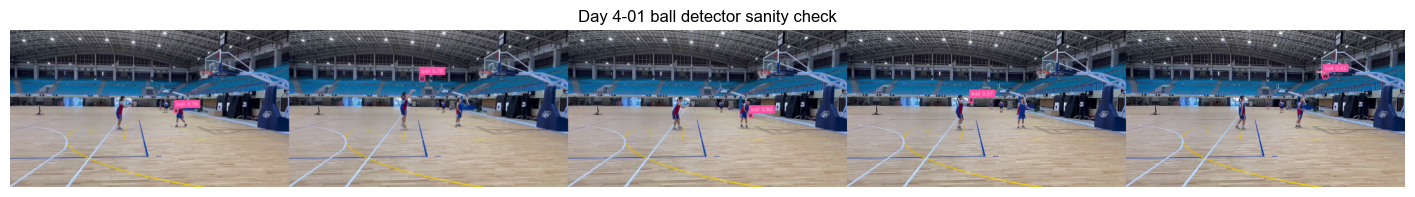

In [4]:
if total_frames <= 0:
    raise RuntimeError("動画の総フレーム数を取得できません。")

# 冒頭の似た画像だけにならないよう、分析範囲から等間隔で抽出します。
sample_stop = max(0, min(total_frames - 1, 180))
frame_indices = sorted({int(value) for value in np.linspace(0, sample_stop, num=5)})
while len(frame_indices) < 5 and frame_indices[-1] < total_frames - 1:
    frame_indices.append(frame_indices[-1] + 1)
frame_indices = frame_indices[:5]

rendered_tiles = []
summary_rows = []
for frame_index in frame_indices:
    image_rgb = read_video_frame(video_path, frame_index=frame_index)
    detections, _ = run_detector_on_image(
        model_path,
        image_rgb,
        conf=SANITY_CONF,
        imgsz=PREVIEW_IMGSZ,
        frame_index=frame_index,
        class_names_override=class_names_override,
        device=DEVICE,
    )
    # この簡易確認では、最高信頼度のボール候補だけを残します。
    detections = [detection for detection in detections if detection.class_name in keep_class_names]
    detections = sorted(detections, key=lambda detection: detection.confidence, reverse=True)[:1]
    visualized_rgb = draw_detection_records(image_rgb, detections)
    rendered_tiles.append(visualized_rgb)
    summary_rows.append({
        "frame": frame_index,
        "detections": len(detections),
        "classes": [detection.class_name for detection in detections],
        "confidences": [round(detection.confidence, 3) for detection in detections],
    })
    print(summary_rows[-1])

# 5 枚を一つの図にし、ダウンロードや発表で使えるようにします。
top_row = side_by_side(rendered_tiles[0], rendered_tiles[1], max_width=2200)
top_row = side_by_side(top_row, rendered_tiles[2], max_width=2200)
bottom_row = side_by_side(rendered_tiles[3], rendered_tiles[4], max_width=2200)
grid_rgb = side_by_side(top_row, bottom_row, max_width=2200)

grid_path = RESULTS / "d4_01_test_infer_grid.png"
save_image_rgb(grid_path, grid_rgb)
print("saved grid:", grid_path)
show_image(grid_rgb, title="Day 4-01 ball detector sanity check", figsize=(18, 12))


## Step 4｜検出器を ByteTrack につなぐ

静止画を確認してから、時間的な連続性を見る。YOLO は各フレームで球を検出し、ByteTrack は矩形の位置、
動き、前後関係から同じ球の `track_id` を維持する。

再生時には矩形の位置、ID の継続、見落とし後の再接続を確認する。この確認動画は各
フレームに最大 1 球だけを残し、検出と追跡の違いを示す。Day 4-03 では全候補を残し、シュートする選手の手首と
イベントの連続性から実際に投げた球の軌跡を選ぶ。


In [5]:
preview_mp4 = RESULTS / "d4_01_bytetrack_ball_preview.mp4"

# 各フレームで YOLO を実行し、検出結果を ByteTrack に渡します。
preview_mp4, preview_records = write_bytetrack_preview_video(
    video_path=video_path,
    model_path=model_path,
    output_path=preview_mp4,
    max_frames=180,
    conf=PREVIEW_CONF,
    imgsz=PREVIEW_IMGSZ,
    class_names_override=class_names_override,
    keep_class_names=keep_class_names,
    max_detections_per_frame=1,
    hold_last_ball_frames=HOLD_LAST_BALL_FRAMES,
    device=DEVICE,
)
preview_json = preview_mp4.with_suffix(".json")

print("saved preview:", preview_mp4)
print("saved json:", preview_json)
print("records:", len(preview_records))
display_video_in_notebook(preview_mp4, width=780, muted=True, loop=True)


$ /opt/homebrew/bin/ffmpeg -y -i /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d4_01_bytetrack_ball_preview.mp4 -an -vcodec libx264 -pix_fmt yuv420p -movflags +faststart -preset veryfast -crf 23 /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d4_01_bytetrack_ball_preview.notebook.mp4


saved preview: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d4_01_bytetrack_ball_preview.mp4
saved json: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d4_01_bytetrack_ball_preview.json
records: 180


## Checks｜次の単元に進む前に

- `using video` が目的の動画で、`assets/converted/` 内にある。
- 確認図に正しい球の矩形が複数あり、見落としと誤検出のフレームを記録した。
- 動画の矩形がおおむね球を追い、track ID の中断を見分けられる。
- 最高スコアだけの確認用 JSON を最終的なシュート軌跡としない。Day 4-03 でシュートごとに球を選び直す。

すべての結果は `assets/results/` にある。次は Day 4-02 で、シュートする選手の骨格、候補区間、
フレームごとの関節角度を求める。
